# Predicting NBA Success Based on Rookie Stats

This notebook represents my workflow and data science techniques in building a sufficent classification model for our target.

Author: Rasheed Martin

## Get the Data
Loading the data from a flat csv to make things simple.

In [33]:
import polars as pl
from pathlib import Path
# Load the data
path = Path.cwd().parent.parent / "data/refined_raw_data" /  "Player_Type_Modeling" / "player_5tier_label_with_target.csv"
df = pl.read_csv(path)
df

Player,Season,Player_Age,2P,2P%,2PA,3P,3P%,3PA,3PAr,AST,AST%,BLK,BLK%,BPM,DBPM,DRB,DRB%,DWS,FG,FG%,FGA,FT,FT%,FTA,FTr,G,GS,MP,OBPM,ORB,ORB%,OWS,PER,PF,PTS,STL,…,FT%_third,FTA_third,FTr_third,G_third,GS_third,MP_third,OBPM_third,ORB_third,ORB%_third,OWS_third,PER_third,PF_third,PTS_third,Player_Age_third,STL_third,STL%_third,TOV_third,TOV%_third,TRB_third,TRB%_third,TS%_third,Trp-Dbl_third,USG%_third,VORP_third,WS_third,WS/48_third,eFG%_third,All_Nba_Team_Max,AllStar_Max,Games_Played_Mean,Win_Share_Sum,Box_Plus_Minus_Mean,Minutes_Played_Mean,Games_Started_Mean,Usage_Mean,Player_Score,Player_Label
str,i64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,…,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,i64,bool,f64,f64,f64,f64,f64,f64,f64,str
"""AC. Green""",2000,37.0,144.0,0.453,318.0,0.0,0.0,6.0,0.019,39.0,4.8,8.0,0.4,-2.2,0.0,206.0,17.3,2.1,144.0,0.444,324.0,79.0,0.712,111.0,0.343,82.0,1.0,1411.0,-2.2,107.0,9.0,1.1,11.2,119.0,367.0,30.0,…,0.712,111.0,0.343,82.0,1.0,1411.0,-2.2,107.0,9.0,1.1,11.2,119.0,367.0,37.0,30.0,1.2,45.0,10.8,313.0,13.2,0.492,0.0,14.4,-0.1,3.2,0.11,0.444,0,false,82.0,3.2,-2.2,1411.0,1.0,14.4,0.2928397,"""Bust Player"""
"""AJ Griffin""",2022,19.0,147.0,0.536,274.0,101.0,0.39,259.0,0.486,73.0,7.0,12.0,0.7,-0.8,-0.5,116.0,9.2,0.9,248.0,0.465,533.0,42.0,0.894,47.0,0.088,72.0,12.0,1401.0,-0.3,37.0,2.9,1.3,12.6,87.0,639.0,42.0,…,1.0,2.0,0.032,20.0,0.0,171.0,-6.0,2.0,1.2,-0.4,1.2,6.0,48.0,20.0,1.0,0.3,8.0,11.3,18.0,5.7,0.382,0.0,17.3,-0.3,-0.4,-0.12,0.371,0,false,46.0,1.8000001,-5.2,786.0,6.0,17.599998,0.289669,"""Bust Player"""
"""AJ Johnson""",2024,20.0,58.0,0.472,123.0,24.0,0.267,90.0,0.423,76.0,17.1,3.0,0.4,-8.1,-2.5,51.0,8.3,0.0,82.0,0.385,213.0,32.0,0.865,37.0,0.174,29.0,11.0,639.0,-5.6,8.0,1.3,-0.5,7.1,50.0,220.0,12.0,…,0.865,37.0,0.174,29.0,11.0,639.0,-5.6,8.0,1.3,-0.5,7.1,50.0,220.0,20.0,12.0,0.9,35.0,13.2,59.0,4.8,0.48,0.0,17.4,-1.0,-0.4,-0.032,0.441,0,false,29.0,-1.2,-8.1,639.0,11.0,17.4,0.281323,"""Bust Player"""
"""AJ. Green""",2022,23.0,9.0,0.45,20.0,44.0,0.419,105.0,0.84,22.0,8.7,0.0,0.0,-0.9,-0.6,39.0,11.3,0.3,53.0,0.424,125.0,4.0,1.0,4.0,0.032,35.0,1.0,345.0,-0.3,6.0,1.9,0.5,11.5,31.0,154.0,6.0,…,0.815,27.0,0.064,73.0,7.0,1659.0,-1.7,18.0,1.2,1.6,9.2,157.0,541.0,25.0,37.0,1.1,40.0,8.4,174.0,5.7,0.621,0.0,12.6,-0.1,2.8,0.082,0.612,0,false,54.666668,4.7,-1.733333,872.6667,2.6666667,14.8,0.285053,"""Bust Player"""
"""AJ. Guyton""",2000,22.0,51.0,0.415,123.0,27.0,0.391,69.0,0.359,64.0,18.1,5.0,0.6,-4.0,-3.2,26.0,5.1,-0.1,78.0,0.406,192.0,15.0,0.833,18.0,0.094,33.0,8.0,630.0,-0.8,10.0,1.8,0.4,10.3,35.0,198.0,9.0,…,null,0.0,0.0,2.0,0.0,9.0,-14.1,0.0,0.0,-0.1,-9.0,0.0,0.0,24.0,1.0,5.7,1.0,20.0,0.0,0.0,0.0,0.0,23.6,0.0,-0.1,-0.45,0.0,0,false,26.666666,0.3,-7.333334,415.33334,4.6666665,20.766668,0.2819847,"""Bust Player"""
…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…
"""Zoran Dragic""",2014,25.0,8.0,0.5,16.0,3.0,0.214,14.0,0.467,5.0,11.2,0.0,0.0,-7.7,-3.6,3.0,4.6,0.0,11.0,0.367,30.0,3.0,0.6,5.0,0.167,16.0,1.0,75.0,-4.1,5.0,7.8,-0.1,8.2,6.0,28.0,2.0,…,0.6,5.0,0.167,16.0,1.0,75.0,-4.1,5.0,7.8,-0.1,8.2,6.0,28.0,25.0,2.0,1.4,5.0,13.4,8.0,6.2,0.435,0.0,22.9,-0.1,-0.1,-0.042,0.417,0,false,16.0,-0.1,-7.7,75.0,1.0,22.9,0.271411,"""Bust Player"""
"""Zoran Planinic""",2003,21.0,44.0,0.454,97.0,9.0,0.281,32.0,0.248,68.0,23.9,3.0,0.5,-3.4,-0.1,41.0,10.2,0.6,53.0,0.411,129.0,38.0,0.633,60.0,0.465,49.0,1.0,473.0,-3.3,14.0,3.5,0.1,10.0,70.0,153.0,13.0,…,0.697,66.0,0.361,56.0,1.0,596.0,-6.1,14.0,2.7,-0.8,6.9,91.0,191.0,23.0,20.0,1.8,43.0,16.9,74.0,7.3,0.45,0.0,20.2,-0.6,0.1,0.005,0.396,0,false,49.333332,1.6,-3.366667,528.0,3.3333333,20.466667,0.295539,"""Bust Player"""
"""Zydrunas Ilgauskas""",2000,25.0,114.0,0.491,232.0,0.0,0.0,2.0,0.009,18.0,5.4,37.0,4.4,-1.8,-0.4,9

## Clean the Data

In [34]:
nulls = df.null_count()
df.null_count().transpose(header_name="Columns", include_header=True).rename({"column_0": "Null Count"}).sort("Null Count", descending=True).filter(pl.col("Null Count") > 0)


Columns,Null Count
str,u32
"""ROY_Rank""",2285
"""ROY_Votes""",2285
"""ROY_Point_Share""",2285
"""All_Rookie_Rank""",1929
"""All_Rookie_First_Place_Votes""",1929
…,…
"""USG%_third""",3
"""WS/48_third""",3
"""Box_Plus_Minus_Mean""",2


In [35]:
import numpy as np
# Fill nulls and clean the data
cleaned_df = df.with_columns(
    *[pl.col(col).fill_null(float("-inf")) for col in df.columns if col.endswith(("_growth_y1_y2", "_growth_y2_y3", "_avg_yoy_growth"))],
    pl.when(pl.col("Draft_Pick").is_null()).then(1000).otherwise(pl.col("Draft_Pick")).alias("Draft_Pick"),
    pl.when(pl.col("Draft_Class").is_null()).then(0).otherwise(1).alias("Was_Drafted"),
    pl.when(pl.col("Draft_Class").is_null()).then(-1).otherwise(pl.col("Draft_Class")).alias("Draft_Class"),
    pl.when(pl.col("All_Rookie_Rank").is_null()).then(pl.lit("No Votes")).otherwise(pl.col("All_Rookie_Rank")).alias("All_Rookie_Rank"),
    pl.when(pl.col("ROY_Rank").is_null()).then(0).otherwise(pl.col("ROY_Rank")).alias("ROY_Rank"),
    pl.when(pl.col("ROY_Votes").is_null()).then(0).otherwise(pl.col("ROY_Votes")).alias("ROY_Votes"),
    pl.when(pl.col("ROY_Point_Share").is_null()).then(0).otherwise(pl.col("ROY_Point_Share")).alias("ROY_Point_Share"),
    pl.when(pl.col("All_Rookie_First_Place_Votes").is_null()).then(0).otherwise(pl.col("All_Rookie_First_Place_Votes")).alias("All_Rookie_First_Place_Votes"),
    pl.when(pl.col("All_Rookie_Second_Place_Votes").is_null()).then(0).otherwise(pl.col("All_Rookie_Second_Place_Votes")).alias("All_Rookie_Second_Place_Votes"),
    pl.when(pl.col("All_Rookie_Point_Share").is_null()).then(0).otherwise(pl.col("All_Rookie_Point_Share")).alias("All_Rookie_Point_Share"),
    pl.col("team_made_playoffs_last_year").fill_null(False).alias("team_made_playoffs_last_year")
)
cleaned_df = cleaned_df.fill_null(0)
numeric_cols = cleaned_df.select(pl.selectors.numeric()).columns
cleaned_df = cleaned_df.with_columns(
    *[pl.when((pl.col(col) == float("inf")) | (pl.col(col) == float("-inf")) | (pl.col(col) == np.nan))
      .then(0).otherwise(pl.col(col)).alias(col) for col in numeric_cols]
)
# These features are redundant with the target label. Ideally, they should not be included in the flat file, but it's acceptable for now.
cleaned_df = cleaned_df.drop(['Games_Played_Mean',
 'Win_Share_Sum',
 'Box_Plus_Minus_Mean',
 'Minutes_Played_Mean',
 'Games_Started_Mean',
 'Usage_Mean',
 'Player_Score',
 'All_Nba_Team_Max',
 'AllStar_Max'], strict=False)

In [36]:
nulls = cleaned_df.null_count()
nulls.transpose(header_name="Columns", include_header=True).rename({"column_0": "Null Count"}).sort("Null Count", descending=True).filter(pl.col("Null Count") > 0)

Columns,Null Count
str,u32


## Feature Selection

We'll reduce the dataset to the most relevant features to improve model quality and efficiency.

In [37]:
cleaned_df

Player,Season,Player_Age,2P,2P%,2PA,3P,3P%,3PA,3PAr,AST,AST%,BLK,BLK%,BPM,DBPM,DRB,DRB%,DWS,FG,FG%,FGA,FT,FT%,FTA,FTr,G,GS,MP,OBPM,ORB,ORB%,OWS,PER,PF,PTS,STL,…,DBPM_third,DRB_third,DRB%_third,DWS_third,FG_third,FG%_third,FGA_third,FT_third,FT%_third,FTA_third,FTr_third,G_third,GS_third,MP_third,OBPM_third,ORB_third,ORB%_third,OWS_third,PER_third,PF_third,PTS_third,Player_Age_third,STL_third,STL%_third,TOV_third,TOV%_third,TRB_third,TRB%_third,TS%_third,Trp-Dbl_third,USG%_third,VORP_third,WS_third,WS/48_third,eFG%_third,Player_Label,Was_Drafted
str,i64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,…,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,str,i32
"""AC. Green""",2000,37.0,144.0,0.453,318.0,0.0,0.0,6.0,0.019,39.0,4.8,8.0,0.4,-2.2,0.0,206.0,17.3,2.1,144.0,0.444,324.0,79.0,0.712,111.0,0.343,82.0,1.0,1411.0,-2.2,107.0,9.0,1.1,11.2,119.0,367.0,30.0,…,0.0,206.0,17.3,2.1,144.0,0.444,324.0,79.0,0.712,111.0,0.343,82.0,1.0,1411.0,-2.2,107.0,9.0,1.1,11.2,119.0,367.0,37.0,30.0,1.2,45.0,10.8,313.0,13.2,0.492,0.0,14.4,-0.1,3.2,0.11,0.444,"""Bust Player""",0
"""AJ Griffin""",2022,19.0,147.0,0.536,274.0,101.0,0.39,259.0,0.486,73.0,7.0,12.0,0.7,-0.8,-0.5,116.0,9.2,0.9,248.0,0.465,533.0,42.0,0.894,47.0,0.088,72.0,12.0,1401.0,-0.3,37.0,2.9,1.3,12.6,87.0,639.0,42.0,…,-3.5,16.0,10.6,0.0,18.0,0.29,62.0,2.0,1.0,2.0,0.032,20.0,0.0,171.0,-6.0,2.0,1.2,-0.4,1.2,6.0,48.0,20.0,1.0,0.3,8.0,11.3,18.0,5.7,0.382,0.0,17.3,-0.3,-0.4,-0.12,0.371,"""Bust Player""",1
"""AJ Johnson""",2024,20.0,58.0,0.472,123.0,24.0,0.267,90.0,0.423,76.0,17.1,3.0,0.4,-8.1,-2.5,51.0,8.3,0.0,82.0,0.385,213.0,32.0,0.865,37.0,0.174,29.0,11.0,639.0,-5.6,8.0,1.3,-0.5,7.1,50.0,220.0,12.0,…,-2.5,51.0,8.3,0.0,82.0,0.385,213.0,32.0,0.865,37.0,0.174,29.0,11.0,639.0,-5.6,8.0,1.3,-0.5,7.1,50.0,220.0,20.0,12.0,0.9,35.0,13.2,59.0,4.8,0.48,0.0,17.4,-1.0,-0.4,-0.032,0.441,"""Bust Player""",1
"""AJ. Green""",2022,23.0,9.0,0.45,20.0,44.0,0.419,105.0,0.84,22.0,8.7,0.0,0.0,-0.9,-0.6,39.0,11.3,0.3,53.0,0.424,125.0,4.0,1.0,4.0,0.032,35.0,1.0,345.0,-0.3,6.0,1.9,0.5,11.5,31.0,154.0,6.0,…,-0.4,156.0,9.8,1.3,182.0,0.429,424.0,22.0,0.815,27.0,0.064,73.0,7.0,1659.0,-1.7,18.0,1.2,1.6,9.2,157.0,541.0,25.0,37.0,1.1,40.0,8.4,174.0,5.7,0.621,0.0,12.6,-0.1,2.8,0.082,0.612,"""Bust Player""",0
"""AJ. Guyton""",2000,22.0,51.0,0.415,123.0,27.0,0.391,69.0,0.359,64.0,18.1,5.0,0.6,-4.0,-3.2,26.0,5.1,-0.1,78.0,0.406,192.0,15.0,0.833,18.0,0.094,33.0,8.0,630.0,-0.8,10.0,1.8,0.4,10.3,35.0,198.0,9.0,…,-2.3,0.0,0.0,0.0,0.0,0.0,4.0,0.0,0.0,0.0,0.0,2.0,0.0,9.0,-14.1,0.0,0.0,-0.1,-9.0,0.0,0.0,24.0,1.0,5.7,1.0,20.0,0.0,0.0,0.0,0.0,23.6,0.0,-0.1,-0.45,0.0,"""Bust Player""",0
…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…
"""Zoran Dragic""",2014,25.0,8.0,0.5,16.0,3.0,0.214,14.0,0.467,5.0,11.2,0.0,0.0,-7.7,-3.6,3.0,4.6,0.0,11.0,0.367,30.0,3.0,0.6,5.0,0.167,16.0,1.0,75.0,-4.1,5.0,7.8,-0.1,8.2,6.0,28.0,2.0,…,-3.6,3.0,4.6,0.0,11.0,0.367,30.0,3.0,0.6,5.0,0.167,16.0,1.0,75.0,-4.1,5.0,7.8,-0.1,8.2,6.0,28.0,25.0,2.0,1.4,5.0,13.4,8.0,6.2,0.435,0.0,22.9,-0.1,-0.1,-0.042,0.417,"""Bust Player""",0
"""Zoran Planinic""",2003,21.0,44.0,0.454,97.0,9.0,0.281,32.0,0.248,68.0,23.9,3.0,0.5,-3.4,-0.1,41.0,10.2,0.6,53.0,0.411,129.0,38.0,0.633,60.0,0.465,49.0,1.0,473.0,-3.3,14.0,3.5,0.1,10.0,70.0,153.0,13.0,…,0.4,60.0,12.0,0.8,66.0,0.361,183.0,46.0,0.697,66.0,0.361,56.0,1.0,596.0,-6.1,14.0,2.7,-0.8,6.9,91.0,191.0,23.0,20.0,1.8,43.0,16.9,74.0,7.3,0.45,0.0,20.2,-0.6,0.1,0.005,0.396,"""Bust Player""",1
"""Zydrunas Ilgauskas""",2000,25.0,114.0,0.491,232.0,0.0,0.0,2.0,0.009,18.0,5.4,37.0,4.4,-1.8,-0.4,95.0,17.8,0.7,114.0,0.487,234.0,53.0,0.679,78.0,0.333,24.0,24.0,616.0,-1.4,65.0,12.3,0.1,16.0,78.0,281.0,15.0,…,-0.8,371.0,17.4,2.1,495.0,0.441,1122.0,400.0,0.781,512.0,0.4

In [38]:
from sklearn.feature_selection import VarianceThreshold
import numpy as np


selector = VarianceThreshold(threshold=0.01)
X = cleaned_df.select(pl.exclude([pl.String, pl.Boolean]))

# Exclude non-numeric columns 
numeric_df = cleaned_df.select(pl.exclude([pl.String, pl.Boolean]))

# Convert to NumPy for sklearn
X_np = numeric_df.to_numpy()

# Remove inf values if any remain
X_np = np.nan_to_num(X_np, nan=0.0, posinf=0.0, neginf=0.0)

# Apply VarianceThreshold
selector = VarianceThreshold(threshold=0.01)
X_reduced_np = selector.fit_transform(X_np)

# Get selected column names
selected_columns = [col for col, keep in zip(numeric_df.columns, selector.get_support()) if keep]

# Reconstruct a Polars DataFrame with selected columns
reduced_df = pl.DataFrame(X_reduced_np, schema=selected_columns)


In [39]:
unimportant_columns = set(numeric_df.columns) - set(selected_columns)
unimportant_columns

set()

In [40]:
cleaned_df = cleaned_df.drop(unimportant_columns, strict=False)
cleaned_df

Player,Season,Player_Age,2P,2P%,2PA,3P,3P%,3PA,3PAr,AST,AST%,BLK,BLK%,BPM,DBPM,DRB,DRB%,DWS,FG,FG%,FGA,FT,FT%,FTA,FTr,G,GS,MP,OBPM,ORB,ORB%,OWS,PER,PF,PTS,STL,…,DBPM_third,DRB_third,DRB%_third,DWS_third,FG_third,FG%_third,FGA_third,FT_third,FT%_third,FTA_third,FTr_third,G_third,GS_third,MP_third,OBPM_third,ORB_third,ORB%_third,OWS_third,PER_third,PF_third,PTS_third,Player_Age_third,STL_third,STL%_third,TOV_third,TOV%_third,TRB_third,TRB%_third,TS%_third,Trp-Dbl_third,USG%_third,VORP_third,WS_third,WS/48_third,eFG%_third,Player_Label,Was_Drafted
str,i64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,…,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,str,i32
"""AC. Green""",2000,37.0,144.0,0.453,318.0,0.0,0.0,6.0,0.019,39.0,4.8,8.0,0.4,-2.2,0.0,206.0,17.3,2.1,144.0,0.444,324.0,79.0,0.712,111.0,0.343,82.0,1.0,1411.0,-2.2,107.0,9.0,1.1,11.2,119.0,367.0,30.0,…,0.0,206.0,17.3,2.1,144.0,0.444,324.0,79.0,0.712,111.0,0.343,82.0,1.0,1411.0,-2.2,107.0,9.0,1.1,11.2,119.0,367.0,37.0,30.0,1.2,45.0,10.8,313.0,13.2,0.492,0.0,14.4,-0.1,3.2,0.11,0.444,"""Bust Player""",0
"""AJ Griffin""",2022,19.0,147.0,0.536,274.0,101.0,0.39,259.0,0.486,73.0,7.0,12.0,0.7,-0.8,-0.5,116.0,9.2,0.9,248.0,0.465,533.0,42.0,0.894,47.0,0.088,72.0,12.0,1401.0,-0.3,37.0,2.9,1.3,12.6,87.0,639.0,42.0,…,-3.5,16.0,10.6,0.0,18.0,0.29,62.0,2.0,1.0,2.0,0.032,20.0,0.0,171.0,-6.0,2.0,1.2,-0.4,1.2,6.0,48.0,20.0,1.0,0.3,8.0,11.3,18.0,5.7,0.382,0.0,17.3,-0.3,-0.4,-0.12,0.371,"""Bust Player""",1
"""AJ Johnson""",2024,20.0,58.0,0.472,123.0,24.0,0.267,90.0,0.423,76.0,17.1,3.0,0.4,-8.1,-2.5,51.0,8.3,0.0,82.0,0.385,213.0,32.0,0.865,37.0,0.174,29.0,11.0,639.0,-5.6,8.0,1.3,-0.5,7.1,50.0,220.0,12.0,…,-2.5,51.0,8.3,0.0,82.0,0.385,213.0,32.0,0.865,37.0,0.174,29.0,11.0,639.0,-5.6,8.0,1.3,-0.5,7.1,50.0,220.0,20.0,12.0,0.9,35.0,13.2,59.0,4.8,0.48,0.0,17.4,-1.0,-0.4,-0.032,0.441,"""Bust Player""",1
"""AJ. Green""",2022,23.0,9.0,0.45,20.0,44.0,0.419,105.0,0.84,22.0,8.7,0.0,0.0,-0.9,-0.6,39.0,11.3,0.3,53.0,0.424,125.0,4.0,1.0,4.0,0.032,35.0,1.0,345.0,-0.3,6.0,1.9,0.5,11.5,31.0,154.0,6.0,…,-0.4,156.0,9.8,1.3,182.0,0.429,424.0,22.0,0.815,27.0,0.064,73.0,7.0,1659.0,-1.7,18.0,1.2,1.6,9.2,157.0,541.0,25.0,37.0,1.1,40.0,8.4,174.0,5.7,0.621,0.0,12.6,-0.1,2.8,0.082,0.612,"""Bust Player""",0
"""AJ. Guyton""",2000,22.0,51.0,0.415,123.0,27.0,0.391,69.0,0.359,64.0,18.1,5.0,0.6,-4.0,-3.2,26.0,5.1,-0.1,78.0,0.406,192.0,15.0,0.833,18.0,0.094,33.0,8.0,630.0,-0.8,10.0,1.8,0.4,10.3,35.0,198.0,9.0,…,-2.3,0.0,0.0,0.0,0.0,0.0,4.0,0.0,0.0,0.0,0.0,2.0,0.0,9.0,-14.1,0.0,0.0,-0.1,-9.0,0.0,0.0,24.0,1.0,5.7,1.0,20.0,0.0,0.0,0.0,0.0,23.6,0.0,-0.1,-0.45,0.0,"""Bust Player""",0
…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…
"""Zoran Dragic""",2014,25.0,8.0,0.5,16.0,3.0,0.214,14.0,0.467,5.0,11.2,0.0,0.0,-7.7,-3.6,3.0,4.6,0.0,11.0,0.367,30.0,3.0,0.6,5.0,0.167,16.0,1.0,75.0,-4.1,5.0,7.8,-0.1,8.2,6.0,28.0,2.0,…,-3.6,3.0,4.6,0.0,11.0,0.367,30.0,3.0,0.6,5.0,0.167,16.0,1.0,75.0,-4.1,5.0,7.8,-0.1,8.2,6.0,28.0,25.0,2.0,1.4,5.0,13.4,8.0,6.2,0.435,0.0,22.9,-0.1,-0.1,-0.042,0.417,"""Bust Player""",0
"""Zoran Planinic""",2003,21.0,44.0,0.454,97.0,9.0,0.281,32.0,0.248,68.0,23.9,3.0,0.5,-3.4,-0.1,41.0,10.2,0.6,53.0,0.411,129.0,38.0,0.633,60.0,0.465,49.0,1.0,473.0,-3.3,14.0,3.5,0.1,10.0,70.0,153.0,13.0,…,0.4,60.0,12.0,0.8,66.0,0.361,183.0,46.0,0.697,66.0,0.361,56.0,1.0,596.0,-6.1,14.0,2.7,-0.8,6.9,91.0,191.0,23.0,20.0,1.8,43.0,16.9,74.0,7.3,0.45,0.0,20.2,-0.6,0.1,0.005,0.396,"""Bust Player""",1
"""Zydrunas Ilgauskas""",2000,25.0,114.0,0.491,232.0,0.0,0.0,2.0,0.009,18.0,5.4,37.0,4.4,-1.8,-0.4,95.0,17.8,0.7,114.0,0.487,234.0,53.0,0.679,78.0,0.333,24.0,24.0,616.0,-1.4,65.0,12.3,0.1,16.0,78.0,281.0,15.0,…,-0.8,371.0,17.4,2.1,495.0,0.441,1122.0,400.0,0.781,512.0,0.4

Encoding Variables

In [41]:
from sklearn.preprocessing import OrdinalEncoder

# 1. Encode Player_Label
player_label_order = [["Bust Player", "Role Player", "Star Player", "All Star Caliber", "All NBA Caliber"]]
player_label_encoder = OrdinalEncoder(categories=player_label_order)

player_labels = cleaned_df["Player_Label"].to_list()
player_labels_encoded = player_label_encoder.fit_transform([[label] for label in player_labels])

# 2. Encode All_Rookie_Rank
rookie_rank_order = [["No Votes", "Received Votes", "1ST Team", "2ND Team"]]
rookie_rank_encoder = OrdinalEncoder(categories=rookie_rank_order)

rookie_ranks = cleaned_df["All_Rookie_Rank"].to_list()
rookie_ranks_encoded = rookie_rank_encoder.fit_transform([[rank] for rank in rookie_ranks])

# 3. Add encoded columns back
cleaned_df = cleaned_df.with_columns([
    pl.Series("Player_Label_Encoded", [val[0] for val in player_labels_encoded]),
    pl.Series("All_Rookie_Rank_Encoded", [val[0] for val in rookie_ranks_encoded])
])

# Use this for your model
y_encoded = cleaned_df["Player_Label_Encoded"].to_numpy()


In [42]:
from sklearn.preprocessing import LabelEncoder

player_names = cleaned_df["Player"].to_list()
teams = cleaned_df["Team"].to_list()

name_encoder = LabelEncoder()
name_encoded = name_encoder.fit_transform(player_names)

team_encoder = LabelEncoder()
team_encoded = team_encoder.fit_transform(teams)

cleaned_df = cleaned_df.with_columns([
    pl.Series("Player_Name_Encoded", name_encoded),
    pl.Series("Team_Encoded", team_encoded)
])

Preparing and using correlation with target variable to narrow down features

In [43]:
# Looking at columns that are highly correlated with each other
excluded_columns = cleaned_df.select(pl.selectors.string() | pl.selectors.boolean()).columns
cleaned_numeric_df = cleaned_df.select(pl.exclude(excluded_columns))

correlation_matrix = cleaned_numeric_df.corr()
correlation_matrix

Season,Player_Age,2P,2P%,2PA,3P,3P%,3PA,3PAr,AST,AST%,BLK,BLK%,BPM,DBPM,DRB,DRB%,DWS,FG,FG%,FGA,FT,FT%,FTA,FTr,G,GS,MP,OBPM,ORB,ORB%,OWS,PER,PF,PTS,STL,STL%,…,DWS_third,FG_third,FG%_third,FGA_third,FT_third,FT%_third,FTA_third,FTr_third,G_third,GS_third,MP_third,OBPM_third,ORB_third,ORB%_third,OWS_third,PER_third,PF_third,PTS_third,Player_Age_third,STL_third,STL%_third,TOV_third,TOV%_third,TRB_third,TRB%_third,TS%_third,Trp-Dbl_third,USG%_third,VORP_third,WS_third,WS/48_third,eFG%_third,Was_Drafted,Player_Label_Encoded,All_Rookie_Rank_Encoded,Player_Name_Encoded,Team_Encoded
f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,…,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64
1.0,-0.406,-0.282397,0.102104,-0.31434,0.026057,0.108043,0.040417,0.441053,-0.198047,-0.083189,-0.185725,0.056584,-0.083136,-0.060878,-0.237791,0.018643,-0.281982,-0.236525,-0.043986,-0.241926,-0.287132,-0.072218,-0.292669,-0.169224,-0.293153,-0.223833,-0.283066,-0.08006,-0.261061,-0.069494,-0.254694,-0.084446,-0.321296,-0.233403,-0.264799,-0.013582,…,-0.201735,-0.166048,-0.012804,-0.179134,-0.214126,-0.06128,-0.220887,-0.127696,-0.22665,-0.184701,-0.223604,-0.074101,-0.196235,-0.047096,-0.179721,-0.047443,-0.266086,-0.15984,-0.463593,-0.193269,-0.009463,-0.223054,-0.136211,-0.18284,-0.013727,0.059665,-0.002295,-0.05076,-0.162944,-0.203051,-0.051008,0.090893,0.177769,-0.202002,0.058987,0.002215,-0.080993
-0.406,1.0,0.041609,-0.051321,0.056193,-0.041708,-0.03241,-0.062556,-0.070554,0.074472,0.066885,0.001831,-0.084913,0.053451,0.060519,0.051754,-0.037589,0.123963,0.025495,-0.015414,0.026256,0.053268,-0.007214,0.041644,0.008786,0.017326,0.065371,0.064221,0.042683,0.032266,-0.010147,0.18836,0.013685,0.060311,0.026142,0.063779,0.004351,…,-0.093568,-0.173399,-0.094554,-0.160406,-0.140634,-0.072819,-0.149363,-0.017712,-0.09559,-0.111379,-0.118474,-0.075889,-0.113283,-0.014912,-0.076343,-0.105667,-0.101493,-0.173756,0.95062,-0.091865,0.012178,-0.134279,0.081692,-0.136319,-0.073175,-0.111158,-0.073385,-0.155429,-0.062681,-0.090735,-0.043081,-0.113906,-0.561249,-0.14581,-0.271304,-0.01193,0.121415
-0.282397,0.041609,1.0,0.167737,0.992367,0.467478,0.122824,0.487616,-0.215264,0.715016,0.224837,0.63598,0.050955,0.24408,0.083099,0.875737,0.100891,0.789102,0.975857,0.247841,0.952664,0.920864,0.270449,0.927663,0.076727,0.743978,0.828308,0.910728,0.27507,0.76734,0.018858,0.685905,0.353284,0.828577,0.961999,0.803758,0.00958,…,0.601124,0.715045,0.201288,0.707998,0.69525,0.251351,0.701315,0.079744,0.514162,0.6146,0.651036,0.338037,0.524902,-0.006037,0.58765,0.330679,0.582457,0.707345,0.113641,0.57777,0.026778,0.681845,-0.035588,0.612144,0.062781,0.194501,0.258214,0.317325,0.587245,0.641599,0.240632,0.159035,0.080761,0.703819,0.473279,-0.015126,0.026805
0.102104,-0.051321,0.167737,1.0,0.130697,0.084009,0.035047,0.088273,-0.055416,0.075511,-0.005273,0.175619,0.18409,0.295042,0.191233,0.187125,0.137968,0.161657,0.165076,0.842888,0.132834,0.119655,0.236642,0.130437,0.103667,0.215195,0.121028,0.16345,0.294927,0.200195,0.156716,0.189123,0.508195,0.186788,0.155781,0.129612,-0.081323,…,0.159518,0.159576,0.521513,0.140371,0.12071,0.194766,0.13075,0.084597,0.204317,0.133674,0.162959,0.263472,0.196839,0.135738,0.145759,0.338163,0.181542,0.152566,-0.012396,0.130523,-0.016958,0.131874,-0.038733,0.196219,0.177102,0.467658,0.02912,0.069633,0.100352,0.16365,0.315138,0.484438,0.107937,0.148667,0.127118,-0.009908,-0.012236
-0.31434,0.056193,0.992367,0.130697,1.0,0.484098,0.135094,0.505238,-0.20874,0.736172,0.248112,0.603404,0.025008,0.233366,0.073261,0.858218,0.076989,0.779365,0.973397,0.211948,0.964251,0.927467,0.278395,0.929303,0.068035,0.747363,0.828729,0.916755,0.265573,0.739085,-0.004271,0.644136,0.333046,0.82805,0.963048,0.816342,0.01591,…,0.590871,0.708779,0.178423,0.709574,0.694755,0.256051,0

This is the prefered way to break this down. Let's get the top 100 correlated features

In [44]:
# Convert the correlation matrix to long format using unpivot
long_rookie_stats = correlation_matrix.with_columns([
    pl.Series("feature_1", correlation_matrix.columns)
]).unpivot(index=["feature_1"], variable_name="feature_2", value_name="correlation")

# Remove self-correlations
long_rookie_stats = long_rookie_stats.filter(pl.col("feature_1") != pl.col("feature_2"))

long_rookie_stats = long_rookie_stats.with_columns([
    pl.when(pl.col("feature_1") < pl.col("feature_2"))
      .then(pl.col("feature_1") + " vs " + pl.col("feature_2"))
      .otherwise(pl.col("feature_2") + " vs " + pl.col("feature_1"))
      .alias("pair")
]).filter(pl.col("feature_1") == "Player_Label_Encoded")

# Add absolute correlation and sort
long_rookie_stats = long_rookie_stats.with_columns([
    pl.col("correlation").abs().alias("abs_correlation")
]).sort("abs_correlation", descending=True)



long_rookie_stats.head(100).select([
    "pair", "correlation", "abs_correlation"
]).to_pandas().style.background_gradient(cmap='coolwarm', subset=['correlation', 'abs_correlation'])

,pair,correlation,abs_correlation
0,PTS_third vs Player_Label_Encoded,0.830173,0.830173
1,FG_third vs Player_Label_Encoded,0.829715,0.829715
2,FGA_third vs Player_Label_Encoded,0.819000,0.819000
3,2P_third vs Player_Label_Encoded,0.810370,0.810370
4,2PA_third vs Player_Label_Encoded,0.806030,0.806030
5,MP_third vs Player_Label_Encoded,0.797775,0.797775
6,Player_Label_Encoded vs TOV_third,0.796198,0.796198
7,FTA_third vs Player_Label_Encoded,0.788978,0.788978
8,FT_third vs Player_Label_Encoded,0.782718,0.782718
9,Player_Label_Encoded vs WS_third,0.780229,0.780229


After reviewing the top 100 features correlated with the target, a 30% absolute correlation threshold is appropriate. All Rookie Team, Rookie, and Third Year Stats show strong correlation, while growth metrics and ROY features do not.

In [45]:
top_features_above_30_percent = long_rookie_stats.filter(pl.col("abs_correlation") > 0.3).with_columns(
    pl.when(pl.col("feature_1") == "Player_Label_Encoded")
    .then(pl.col("feature_2"))
    .otherwise(pl.col("feature_1")).alias("feature")
)["feature"].unique().to_list()
top_features_above_30_percent

['GS',
 'G',
 'ROY_Point_Share',
 'BPM_third',
 'AST',
 'FG_third',
 '2P',
 'ORB_third',
 'PER_third',
 'PF',
 'FT_third',
 'OBPM_third',
 '2P_third',
 'OWS',
 'MP_third',
 'STL_third',
 'USG%_third',
 'FTA_third',
 'PF_third',
 '3P_third',
 'OWS_third',
 'AST_third',
 'All_Rookie_Point_Share',
 'GS_third',
 'All_Rookie_Rank_Encoded',
 '2PA',
 'DRB_third',
 'TOV',
 '2PA_third',
 'TRB_third',
 'DWS',
 'DWS_third',
 'FT',
 '3P',
 'FGA_third',
 'PTS',
 'FG',
 'FTA',
 '3PA_third',
 'TOV_third',
 'PER',
 'VORP',
 'ROY_Rank',
 'WS/48_third',
 'BLK',
 'WS',
 'FGA',
 'BLK_third',
 'MP',
 'G_third',
 'VORP_third',
 'WS_third',
 'STL',
 'All_Rookie_First_Place_Votes',
 'DRB',
 'ORB',
 'TRB',
 'PTS_third',
 '3PA']

I included context features with lower correlation to the target based on domain knowledge. Higher draft picks and drafted players tend to be more successful. 

In [46]:
X_df = cleaned_df[top_features_above_30_percent + ["team_made_playoffs_last_year", "Draft_Pick", "Was_Drafted"]]
X_np = X_df.to_numpy()

In [47]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.feature_selection import RFECV
from sklearn.model_selection import StratifiedKFold

model = RandomForestClassifier(random_state=42)


rfecv = RFECV(estimator=model, cv=StratifiedKFold(5), scoring='accuracy')
fit = rfecv.fit(X_np, y_encoded)

selected_features = [col for col, keep in zip(X_df.columns, fit.support_) if keep]
X_selected = X_df.select(selected_features)


In [48]:
X_df

GS,G,ROY_Point_Share,BPM_third,AST,FG_third,2P,ORB_third,PER_third,PF,FT_third,OBPM_third,2P_third,OWS,MP_third,STL_third,USG%_third,FTA_third,PF_third,3P_third,OWS_third,AST_third,All_Rookie_Point_Share,GS_third,All_Rookie_Rank_Encoded,2PA,DRB_third,TOV,2PA_third,TRB_third,DWS,DWS_third,FT,3P,FGA_third,PTS,FG,FTA,3PA_third,TOV_third,PER,VORP,ROY_Rank,WS/48_third,BLK,WS,FGA,BLK_third,MP,G_third,VORP_third,WS_third,STL,All_Rookie_First_Place_Votes,DRB,ORB,TRB,PTS_third,3PA,team_made_playoffs_last_year,Draft_Pick,Was_Drafted
f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,i64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,i64,f64,f64,f64,f64,f64,bool,i64,i32
1.0,82.0,0.0,-2.2,39.0,144.0,144.0,107.0,11.2,119.0,79.0,-2.2,144.0,1.1,1411.0,30.0,14.4,111.0,119.0,0.0,1.1,39.0,0.0,1.0,0.0,318.0,206.0,45.0,318.0,313.0,2.1,2.1,79.0,0.0,324.0,367.0,144.0,111.0,6.0,45.0,11.2,-0.1,0,0.11,8.0,3.2,324.0,8.0,1411.0,82.0,-0.1,3.2,30.0,0,206.0,107.0,313.0,367.0,6.0,true,1000,0
12.0,72.0,0.0,-9.6,73.0,18.0,147.0,2.0,1.2,87.0,2.0,-6.0,8.0,1.3,171.0,1.0,17.3,2.0,6.0,10.0,-0.4,5.0,0.13,0.0,1.0,274.0,16.0,42.0,23.0,18.0,0.9,0.0,42.0,101.0,62.0,639.0,248.0,47.0,39.0,8.0,12.6,0.4,0,-0.12,12.0,2.2,533.0,2.0,1401.0,20.0,-0.3,-0.4,42.0,0,116.0,37.0,153.0,48.0,259.0,true,16,1
11.0,29.0,0.0,-8.1,76.0,82.0,58.0,8.0,7.1,50.0,32.0,-5.6,58.0,-0.5,639.0,12.0,17.4,37.0,50.0,24.0,-0.5,76.0,0.0,11.0,0.0,123.0,51.0,35.0,123.0,59.0,0.0,0.0,32.0,24.0,213.0,220.0,82.0,37.0,90.0,35.0,7.1,-1.0,0,-0.032,3.0,-0.4,213.0,3.0,639.0,29.0,-1.0,-0.4,12.0,0,51.0,8.0,59.0,220.0,90.0,false,23,1
1.0,35.0,0.0,-2.2,22.0,182.0,9.0,18.0,9.2,31.0,22.0,-1.7,27.0,0.5,1659.0,37.0,12.6,27.0,157.0,155.0,1.6,108.0,0.0,7.0,0.0,20.0,156.0,9.0,61.0,174.0,0.3,1.3,4.0,44.0,424.0,154.0,53.0,4.0,363.0,40.0,11.5,0.1,0,0.082,0.0,0.8,125.0,7.0,345.0,73.0,-0.1,2.8,6.0,0,39.0,6.0,45.0,541.0,105.0,true,1000,0
8.0,33.0,0.0,-16.4,64.0,0.0,51.0,0.0,-9.0,35.0,0.0,-14.1,0.0,0.4,9.0,1.0,23.6,0.0,0.0,0.0,-0.1,2.0,0.0,0.0,0.0,123.0,0.0,24.0,3.0,0.0,-0.1,0.0,15.0,27.0,4.0,198.0,78.0,18.0,1.0,1.0,10.3,-0.3,0,-0.45,5.0,0.3,192.0,0.0,630.0,2.0,0.0,-0.1,9.0,0,26.0,10.0,36.0,0.0,69.0,false,1000,0
…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…
1.0,16.0,0.0,-7.7,5.0,11.0,8.0,5.0,8.2,6.0,3.0,-4.1,8.0,-0.1,75.0,2.0,22.9,5.0,6.0,3.0,-0.1,5.0,0.0,1.0,0.0,16.0,3.0,5.0,16.0,8.0,0.0,0.0,3.0,3.0,30.0,28.0,11.0,5.0,14.0,5.0,8.2,-0.1,0,-0.042,0.0,-0.1,30.0,0.0,75.0,16.0,-0.1,-0.1,2.0,0,3.0,5.0,8.0,28.0,14.0,false,1000,0
1.0,49.0,0.0,-5.7,68.0,66.0,44.0,14.0,6.9,70.0,46.0,-6.1,53.0,0.1,596.0,20.0,20.2,66.0,91.0,13.0,-0.8,53.0,0.0,1.0,0.0,97.0,60.0,36.0,127.0,74.0,0.6,0.8,38.0,9.0,183.0,153.0,53.0,60.0,56.0,43.0,10.0,-0.2,0,0.005,3.0,0.7,129.0,4.0,473.0,56.0,-0.6,0.1,13.0,0,41.0,14.0,55.0,191.0,32.0,true,22,1
24.0,24.0,0.0,-0.3,18.0,495.0,114.0,240.0,19.4,78.0,400.0,0.5,495.0,0.1,2432.0,56.0,27.8,512.0,274.0,0.0,2.9,127.0,0.0,81.0,0.0,232.0,371.0,60.0,1117.0,611.0,0.7,2.1,53.0,0.0,1122.0,281.0,114.0,78.0,5.0,210.0,16.0,0.0,0,0.099,37.0,0.7,234.0,152.0,616.0,81.0,1.0,5.0,15.0,0,95.0,65.0,160.0,1390.0,2.0,false,1000,0


In [49]:
selected_features = [col for col, keep in zip(X_df.columns, fit.support_) if keep]
X_selected = X_df.select(selected_features)

In [50]:
selected_features

['GS',
 'G',
 'BPM_third',
 'AST',
 'FG_third',
 '2P',
 'ORB_third',
 'PER_third',
 'PF',
 'FT_third',
 'OBPM_third',
 '2P_third',
 'OWS',
 'MP_third',
 'STL_third',
 'USG%_third',
 'FTA_third',
 'PF_third',
 'OWS_third',
 'AST_third',
 'GS_third',
 '2PA',
 'DRB_third',
 'TOV',
 '2PA_third',
 'TRB_third',
 'DWS',
 'DWS_third',
 'FT',
 'FGA_third',
 'PTS',
 'FG',
 'FTA',
 '3PA_third',
 'TOV_third',
 'PER',
 'VORP',
 'WS/48_third',
 'BLK',
 'WS',
 'FGA',
 'BLK_third',
 'MP',
 'G_third',
 'VORP_third',
 'WS_third',
 'STL',
 'DRB',
 'ORB',
 'TRB',
 'PTS_third',
 '3PA',
 'Draft_Pick']

Create Pipeline to make modeling easier in other notebook

In [51]:
import polars as pl
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.ensemble import RandomForestClassifier

In [52]:
import pandas as pd
from sklearn.base import BaseEstimator, TransformerMixin
import numpy as np

class NumericalCustomCleaner(BaseEstimator, TransformerMixin):
    def __init__(self):
        pass

    def fit(self, X, y=None):
        return self

    def transform(self, X):
        # If input is Pandas, convert to Polars
        if isinstance(X, pd.DataFrame):
            X = pl.from_pandas(X)

        X_cleaned = X.with_columns(
            *[pl.when((pl.col(col) == float("inf")) | (pl.col(col) == float("-inf")) | (pl.col(col).is_nan()))
              .then(0).otherwise(pl.col(col)).alias(col) for col in X.columns]
        )

        return X_cleaned.to_numpy()


In [53]:
X = df.drop("Player_Label")
y = df["Player_Label"]

# Outside the pipeline
player_label_order = [["Bust Player", "Role Player", "Star Player", "All Star Caliber", "All NBA Caliber"]]
player_label_encoder = OrdinalEncoder(categories=player_label_order)

y = player_label_encoder.fit_transform(df[["Player_Label"]]).flatten()


In [54]:
X

Player,Season,Player_Age,2P,2P%,2PA,3P,3P%,3PA,3PAr,AST,AST%,BLK,BLK%,BPM,DBPM,DRB,DRB%,DWS,FG,FG%,FGA,FT,FT%,FTA,FTr,G,GS,MP,OBPM,ORB,ORB%,OWS,PER,PF,PTS,STL,…,FT_third,FT%_third,FTA_third,FTr_third,G_third,GS_third,MP_third,OBPM_third,ORB_third,ORB%_third,OWS_third,PER_third,PF_third,PTS_third,Player_Age_third,STL_third,STL%_third,TOV_third,TOV%_third,TRB_third,TRB%_third,TS%_third,Trp-Dbl_third,USG%_third,VORP_third,WS_third,WS/48_third,eFG%_third,All_Nba_Team_Max,AllStar_Max,Games_Played_Mean,Win_Share_Sum,Box_Plus_Minus_Mean,Minutes_Played_Mean,Games_Started_Mean,Usage_Mean,Player_Score
str,i64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,…,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,i64,bool,f64,f64,f64,f64,f64,f64,f64
"""AC. Green""",2000,37.0,144.0,0.453,318.0,0.0,0.0,6.0,0.019,39.0,4.8,8.0,0.4,-2.2,0.0,206.0,17.3,2.1,144.0,0.444,324.0,79.0,0.712,111.0,0.343,82.0,1.0,1411.0,-2.2,107.0,9.0,1.1,11.2,119.0,367.0,30.0,…,79.0,0.712,111.0,0.343,82.0,1.0,1411.0,-2.2,107.0,9.0,1.1,11.2,119.0,367.0,37.0,30.0,1.2,45.0,10.8,313.0,13.2,0.492,0.0,14.4,-0.1,3.2,0.11,0.444,0,false,82.0,3.2,-2.2,1411.0,1.0,14.4,0.2928397
"""AJ Griffin""",2022,19.0,147.0,0.536,274.0,101.0,0.39,259.0,0.486,73.0,7.0,12.0,0.7,-0.8,-0.5,116.0,9.2,0.9,248.0,0.465,533.0,42.0,0.894,47.0,0.088,72.0,12.0,1401.0,-0.3,37.0,2.9,1.3,12.6,87.0,639.0,42.0,…,2.0,1.0,2.0,0.032,20.0,0.0,171.0,-6.0,2.0,1.2,-0.4,1.2,6.0,48.0,20.0,1.0,0.3,8.0,11.3,18.0,5.7,0.382,0.0,17.3,-0.3,-0.4,-0.12,0.371,0,false,46.0,1.8000001,-5.2,786.0,6.0,17.599998,0.289669
"""AJ Johnson""",2024,20.0,58.0,0.472,123.0,24.0,0.267,90.0,0.423,76.0,17.1,3.0,0.4,-8.1,-2.5,51.0,8.3,0.0,82.0,0.385,213.0,32.0,0.865,37.0,0.174,29.0,11.0,639.0,-5.6,8.0,1.3,-0.5,7.1,50.0,220.0,12.0,…,32.0,0.865,37.0,0.174,29.0,11.0,639.0,-5.6,8.0,1.3,-0.5,7.1,50.0,220.0,20.0,12.0,0.9,35.0,13.2,59.0,4.8,0.48,0.0,17.4,-1.0,-0.4,-0.032,0.441,0,false,29.0,-1.2,-8.1,639.0,11.0,17.4,0.281323
"""AJ. Green""",2022,23.0,9.0,0.45,20.0,44.0,0.419,105.0,0.84,22.0,8.7,0.0,0.0,-0.9,-0.6,39.0,11.3,0.3,53.0,0.424,125.0,4.0,1.0,4.0,0.032,35.0,1.0,345.0,-0.3,6.0,1.9,0.5,11.5,31.0,154.0,6.0,…,22.0,0.815,27.0,0.064,73.0,7.0,1659.0,-1.7,18.0,1.2,1.6,9.2,157.0,541.0,25.0,37.0,1.1,40.0,8.4,174.0,5.7,0.621,0.0,12.6,-0.1,2.8,0.082,0.612,0,false,54.666668,4.7,-1.733333,872.6667,2.6666667,14.8,0.285053
"""AJ. Guyton""",2000,22.0,51.0,0.415,123.0,27.0,0.391,69.0,0.359,64.0,18.1,5.0,0.6,-4.0,-3.2,26.0,5.1,-0.1,78.0,0.406,192.0,15.0,0.833,18.0,0.094,33.0,8.0,630.0,-0.8,10.0,1.8,0.4,10.3,35.0,198.0,9.0,…,0.0,null,0.0,0.0,2.0,0.0,9.0,-14.1,0.0,0.0,-0.1,-9.0,0.0,0.0,24.0,1.0,5.7,1.0,20.0,0.0,0.0,0.0,0.0,23.6,0.0,-0.1,-0.45,0.0,0,false,26.666666,0.3,-7.333334,415.33334,4.6666665,20.766668,0.2819847
…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…
"""Zoran Dragic""",2014,25.0,8.0,0.5,16.0,3.0,0.214,14.0,0.467,5.0,11.2,0.0,0.0,-7.7,-3.6,3.0,4.6,0.0,11.0,0.367,30.0,3.0,0.6,5.0,0.167,16.0,1.0,75.0,-4.1,5.0,7.8,-0.1,8.2,6.0,28.0,2.0,…,3.0,0.6,5.0,0.167,16.0,1.0,75.0,-4.1,5.0,7.8,-0.1,8.2,6.0,28.0,25.0,2.0,1.4,5.0,13.4,8.0,6.2,0.435,0.0,22.9,-0.1,-0.1,-0.042,0.417,0,false,16.0,-0.1,-7.7,75.0,1.0,22.9,0.271411
"""Zoran Planinic""",2003,21.0,44.0,0.454,97.0,9.0,0.281,32.0,0.248,68.0,23.9,3.0,0.5,-3.4,-0.1,41.0,10.2,0.6,53.0,0.411,129.0,38.0,0.633,60.0,0.465,49.0,1.0,473.0,-3.3,14.0,3.5,0.1,10.0,70.0,153.0,13.0,…,46.0,0.697,66.0,0.361,56.0,1.0,596.0,-6.1,14.0,2.7,-0.8,6.9,91.0,191.0,23.0,20.0,1.8,43.0,16.9,74.0,7.3,0.45,0.0,20.2,-0.6,0.1,0.005,0.396,0,false,49.333332,1.6,-3.366667,528.0,3.3333333,20.466667,0.295539
"""Zydrunas Ilgauskas""",2000,25.0,114.0,0.491,232.0,0.0,0.0,2.0,0.009,18.0,5.4,37.0,4.4,-1.8,-0.4,95.0,17.8,0.7,114.0,0.487,234.0,53.0,0.679,78.0,0.333,24.0,24.0,616.0,-1.4,65.0,12.3,0.1,16.0,78.0,

In [55]:
numeric_features = [
 'PF',
 '2PA_third',
 'STL_third',
 'WS/48_third',
 'BPM_third',
 'PTS',
 'FGA_third',
 'DRB_third',
 'FT_third',
 '2PA',
 'GS',
 'OBPM_third',
 'FT',
 'DWS_third',
 'FTA',
 'FG_third',
 'FG',
 'DRB',
 'WS_third',
 'USG%_third',
 'TRB_third',
 'AST_third',
 'TOV',
 'PER',
 'MP',
 'PF_third',
 'FTA_third',
 'PER_third',
 '2P_third',
 'PTS_third',
 '2P',
 'FGA',
 'VORP_third',
 'TOV_third',
 'GS_third',
 'MP_third']
categorical_features = X.select(pl.selectors.categorical()).columns


In [56]:
# Numeric preprocessing: fill missing values, scale
numeric_transformer = Pipeline([
    ('numerical_cleaner', NumericalCustomCleaner()),
    ('imputer', SimpleImputer(strategy='constant', fill_value=0)),
    ('scaler', StandardScaler())
])

# Combine into one preprocessor
preprocessor = ColumnTransformer([
    ('num', numeric_transformer, numeric_features),
])


In [57]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, stratify=y, random_state=42)

In [58]:
X_train_processed = preprocessor.fit_transform(X_train)
X_test_processed = preprocessor.transform(X_test)

In [60]:
model = RandomForestClassifier(random_state=42)
model.fit(X_train_processed, y_train)

,n_estimators,100
,criterion,'gini'
,max_depth,None
,min_samples_split,2
,min_samples_leaf,1
,min_weight_fraction_leaf,0.0
,max_features,'sqrt'
,max_leaf_nodes,None
,min_impurity_decrease,0.0
,bootstrap,True
,oob_score,False


In [61]:
from sklearn.metrics import (
    classification_report, 
    confusion_matrix, 
    ConfusionMatrixDisplay, 
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)
import numpy as np
import matplotlib.pyplot as plt
from pipeline import print_roc_curve
from pipeline import print_precision_recall_curve


def print_metrics(y_true, y_pred, target_names):
    print(classification_report(y_true, y_pred, target_names=target_names))

    accuracy = accuracy_score(y_true, y_pred)
    precision = precision_score(y_true, y_pred, average='macro', zero_division=0)
    recall = recall_score(y_true, y_pred, average='macro', zero_division=0)
    f1 = f1_score(y_true, y_pred, average='macro', zero_division=0)

    print("Accuracy:", accuracy)
    print("Precision (macro):", precision)
    print("Recall (macro):", recall)
    print("F1 Score (macro):", f1)

    cm = confusion_matrix(y_true, y_pred)
    disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=target_names)
    disp.plot(cmap='viridis')
    plt.title("Confusion Matrix")
    plt.xlabel("Predicted Label")
    plt.xticks(rotation=45, ha='right')
    plt.show()

                  precision    recall  f1-score   support

     Bust Player       0.89      0.91      0.90       249
     Role Player       0.68      0.74      0.71       136
     Star Player       0.64      0.64      0.64        76
All Star Caliber       0.00      0.00      0.00        14
 All NBA Caliber       0.75      0.43      0.55        21

        accuracy                           0.78       496
       macro avg       0.59      0.55      0.56       496
    weighted avg       0.77      0.78      0.77       496

Accuracy: 0.7782258064516129
Precision (macro): 0.5932579957000252
Recall (macro): 0.5455203831691204
F1 Score (macro): 0.5603095620852239


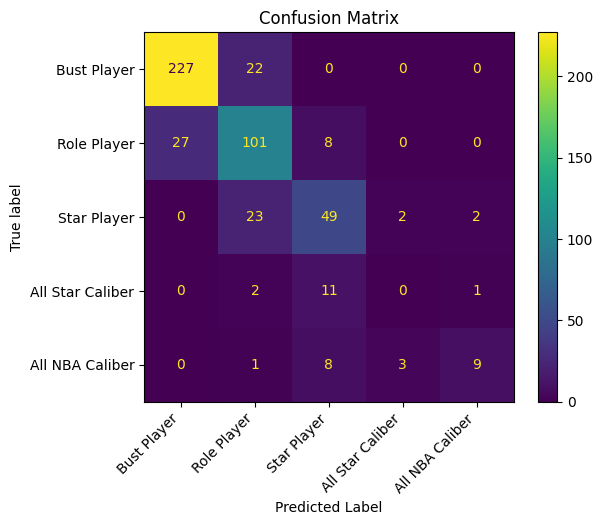

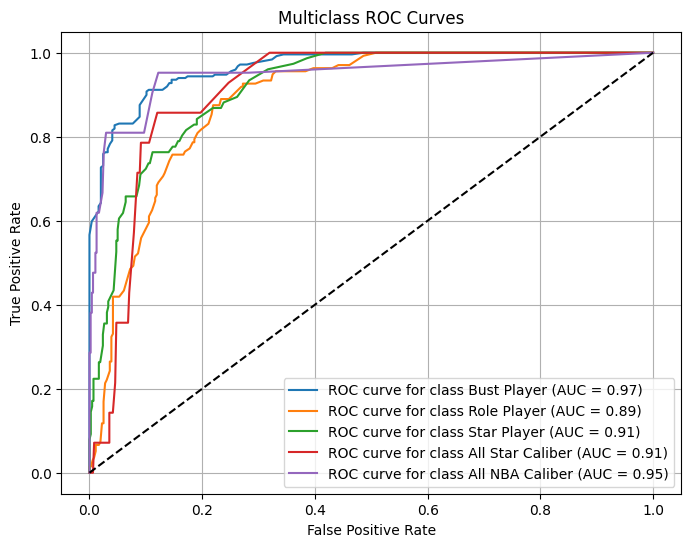

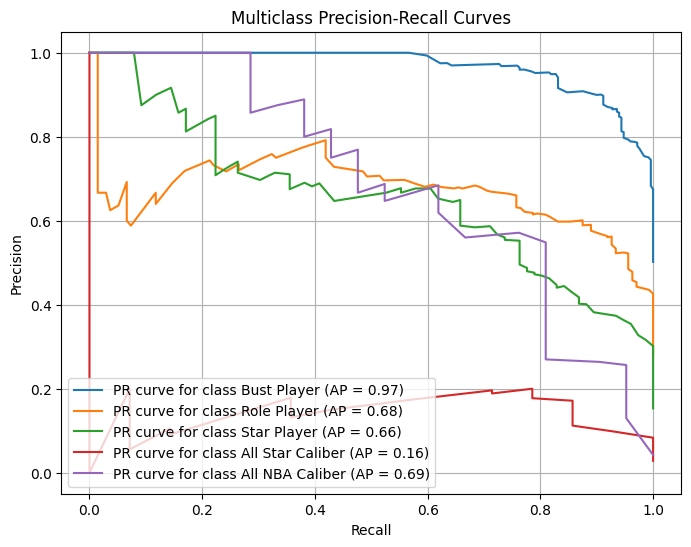

In [62]:
target_names=player_label_encoder.categories_[0] 
y_pred = model.predict(X_test_processed)
print_metrics(y_test, y_pred, target_names)
print_roc_curve(y_test, model, X_test_processed, target_names)
print_precision_recall_curve(y_test, model, X_test_processed, target_names)

/Users/rashe/PycharmProjects/PredictingNBACareers/.venv/lib/python3.13/site-packages/xgboost/training.py:183: UserWarning: [02:19:24] WARNING: /Users/runner/work/xgboost/xgboost/src/learner.cc:738: 
Parameters: { "use_label_encoder" } are not used.

  bst.update(dtrain, iteration=i, fobj=obj)


                  precision    recall  f1-score   support

     Bust Player       0.89      0.91      0.90       249
     Role Player       0.68      0.73      0.70       136
     Star Player       0.62      0.63      0.62        76
All Star Caliber       0.00      0.00      0.00        14
 All NBA Caliber       0.73      0.38      0.50        21

        accuracy                           0.77       496
       macro avg       0.58      0.53      0.55       496
    weighted avg       0.76      0.77      0.76       496

Accuracy: 0.7701612903225806
Precision (macro): 0.5831224083556741
Recall (macro): 0.5304238182273543
F1 Score (macro): 0.5457593217379694


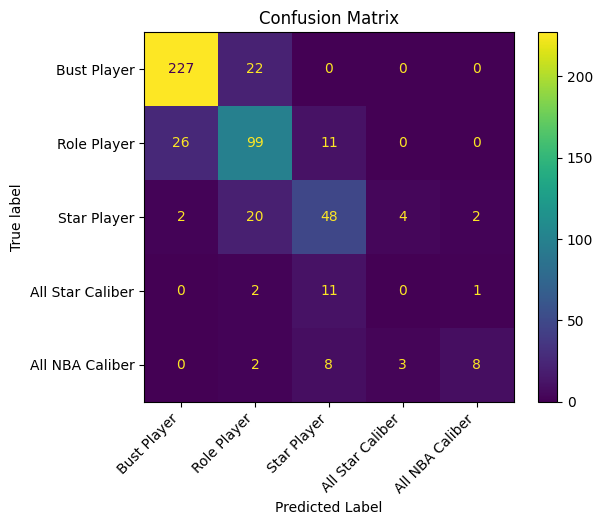

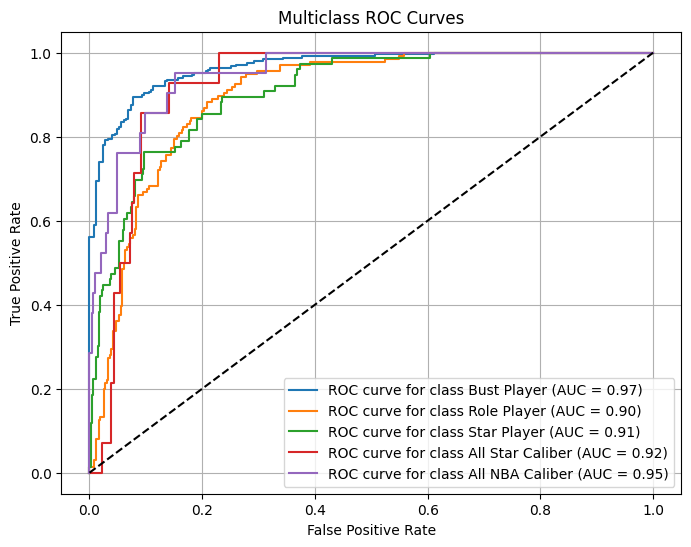

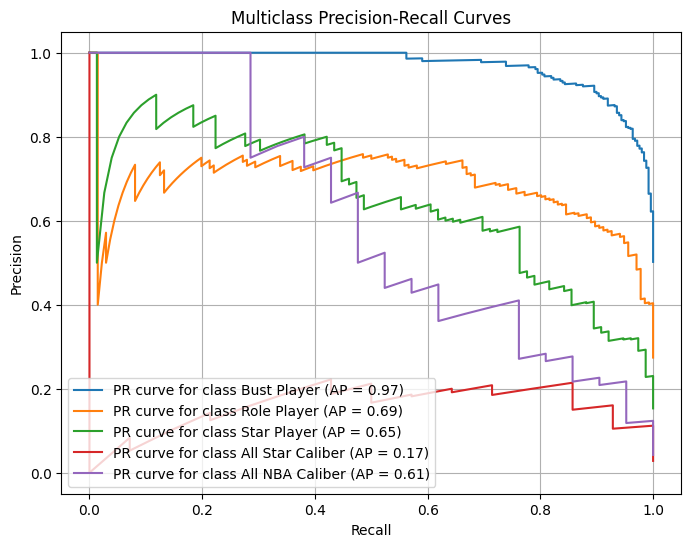

In [30]:
from xgboost import XGBClassifier

model = XGBClassifier(use_label_encoder=True, eval_metric='mlogloss')
model.fit(X_train_processed, y_train)
preds = model.predict(X_test_processed)
print_metrics(y_test, preds, target_names)
print_roc_curve(y_test, model, X_test_processed, target_names)
print_precision_recall_curve(y_test, model, X_test_processed, target_names)

Fold 1 Report
                  precision    recall  f1-score   support

     Bust Player       0.89      0.93      0.91       249
     Role Player       0.68      0.70      0.69       136
     Star Player       0.57      0.62      0.59        76
All Star Caliber       0.50      0.07      0.12        14
 All NBA Caliber       0.91      0.48      0.62        21

        accuracy                           0.77       496
       macro avg       0.71      0.56      0.59       496
    weighted avg       0.77      0.77      0.76       496

Accuracy: 0.7741935483870968
Precision (macro): 0.7084777872729681
Recall (macro): 0.5584560710777653
F1 Score (macro): 0.5874525696339286


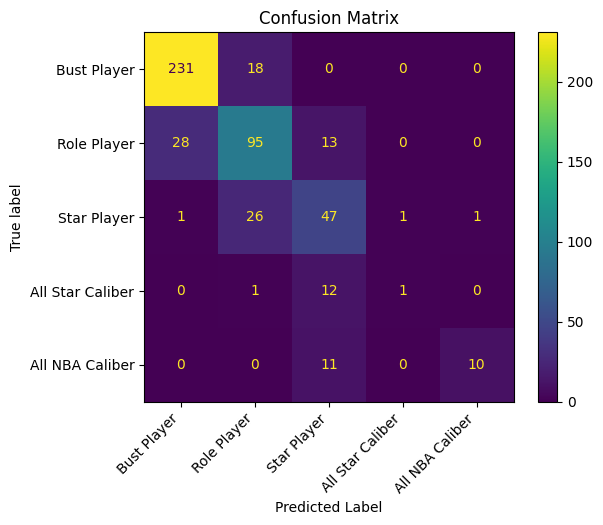

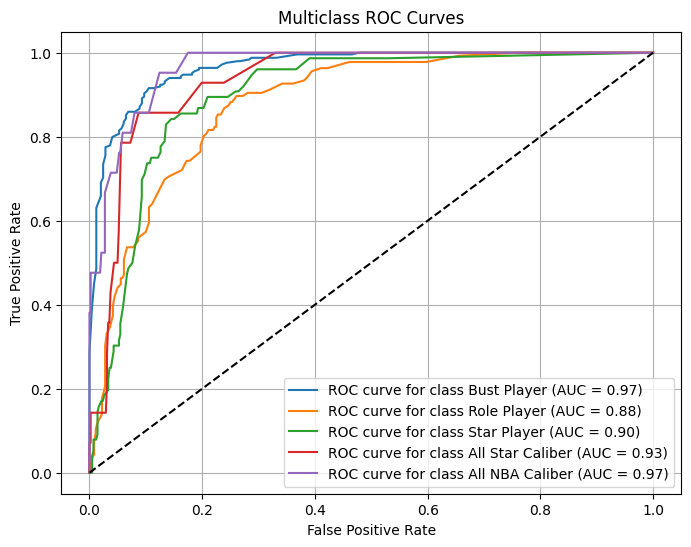

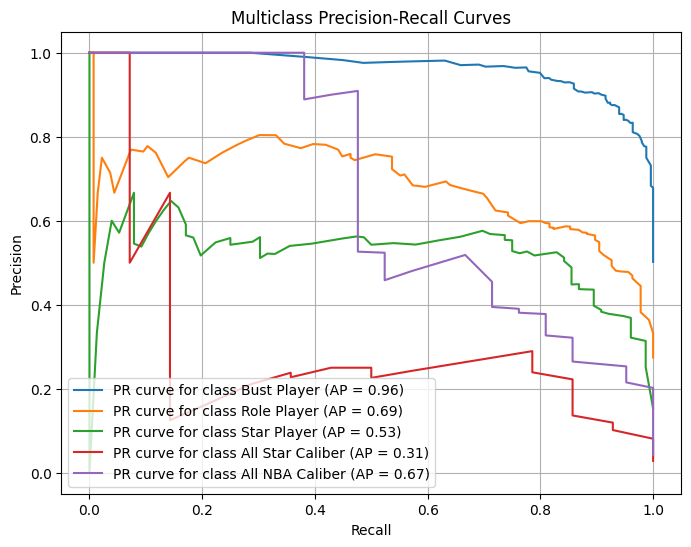



Fold 2 Report
                  precision    recall  f1-score   support

     Bust Player       0.89      0.93      0.91       249
     Role Player       0.70      0.69      0.70       136
     Star Player       0.62      0.66      0.64        76
All Star Caliber       0.67      0.15      0.25        13
 All NBA Caliber       0.76      0.62      0.68        21

        accuracy                           0.79       495
       macro avg       0.73      0.61      0.64       495
    weighted avg       0.78      0.79      0.78       495

Accuracy: 0.7878787878787878
Precision (macro): 0.7285845115194817
Recall (macro): 0.6099351647395215
F1 Score (macro): 0.6354829633157807


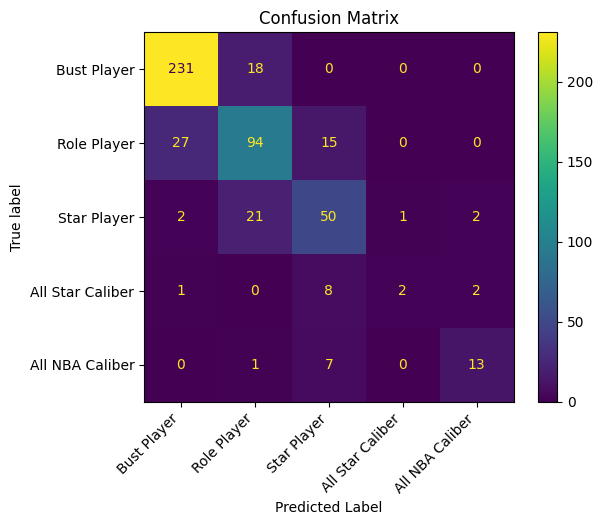

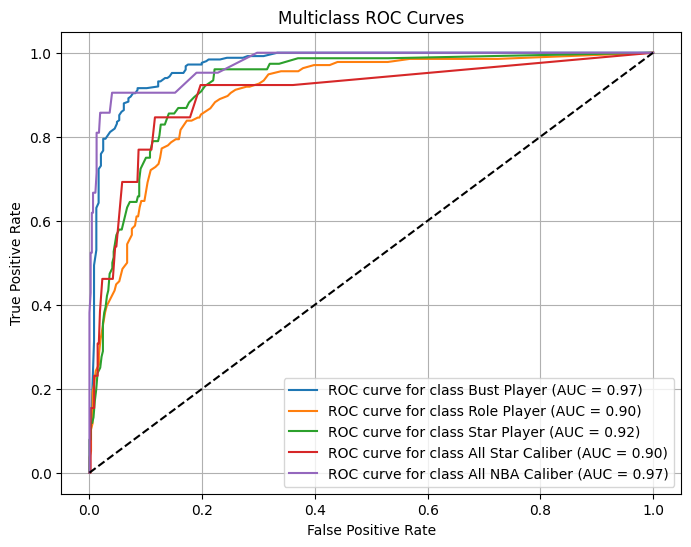

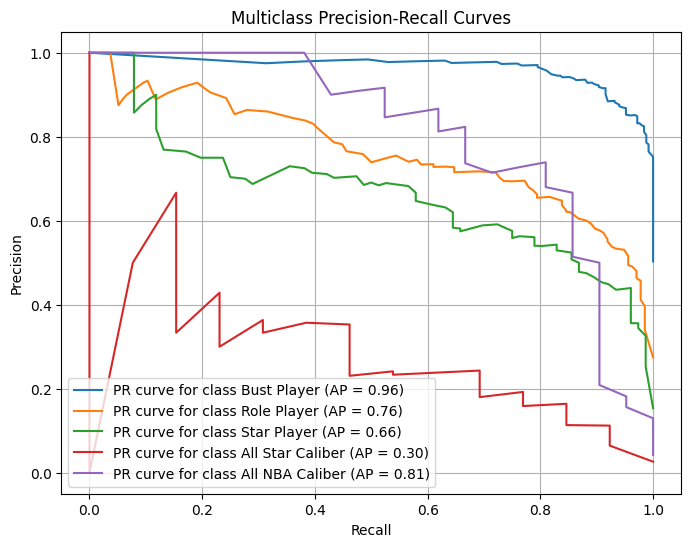



Fold 3 Report
                  precision    recall  f1-score   support

     Bust Player       0.92      0.92      0.92       249
     Role Player       0.65      0.76      0.71       136
     Star Player       0.62      0.59      0.60        75
All Star Caliber       1.00      0.15      0.27        13
 All NBA Caliber       0.71      0.45      0.56        22

        accuracy                           0.78       495
       macro avg       0.78      0.58      0.61       495
    weighted avg       0.79      0.78      0.78       495

Accuracy: 0.7838383838383839
Precision (macro): 0.7807509450123489
Recall (macro): 0.5750853616027252
F1 Score (macro): 0.6091418689229482


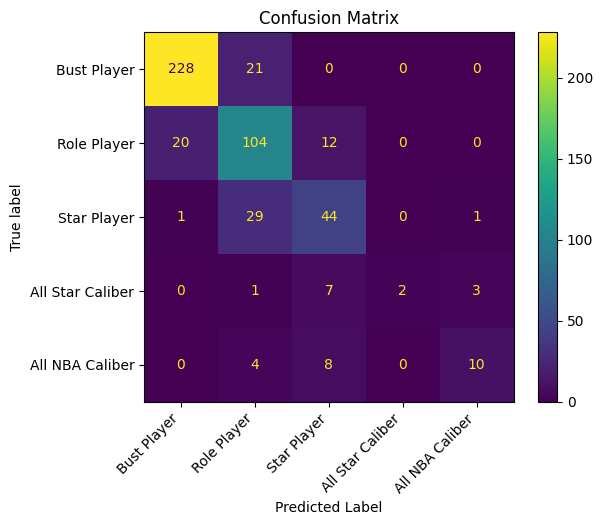

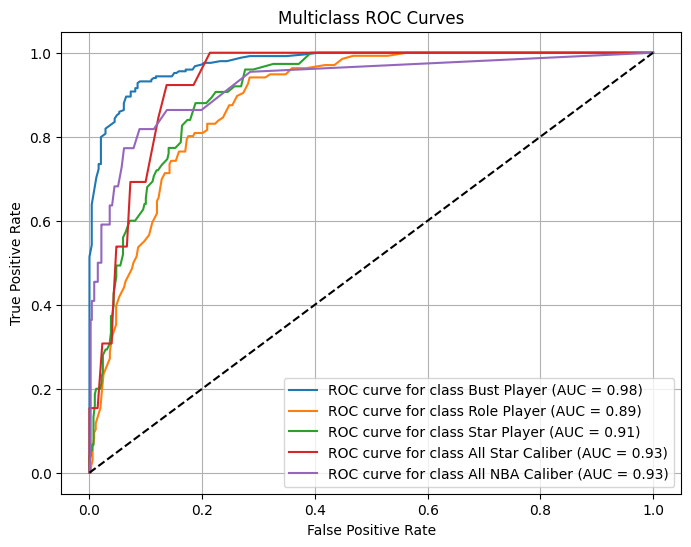

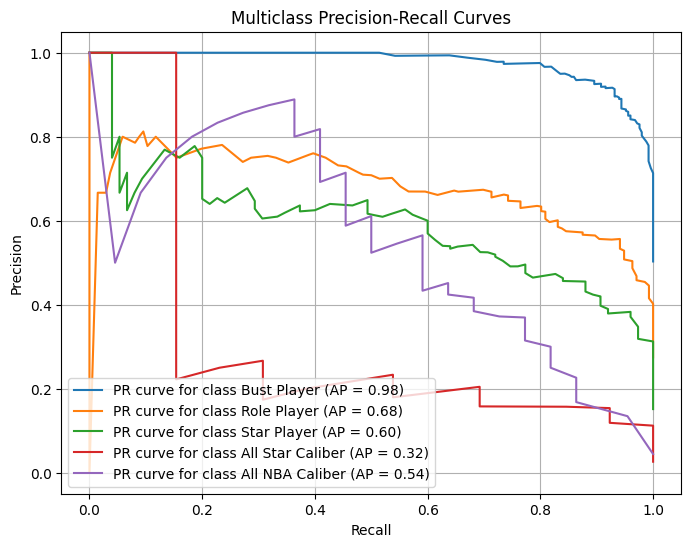



Fold 4 Report
                  precision    recall  f1-score   support

     Bust Player       0.89      0.93      0.91       249
     Role Player       0.65      0.68      0.67       136
     Star Player       0.56      0.55      0.55        75
All Star Caliber       0.50      0.07      0.12        14
 All NBA Caliber       0.72      0.62      0.67        21

        accuracy                           0.77       495
       macro avg       0.67      0.57      0.58       495
    weighted avg       0.76      0.77      0.76       495

Accuracy: 0.7656565656565657
Precision (macro): 0.6652215200160405
Recall (macro): 0.5697354459856232
F1 Score (macro): 0.584367241257005


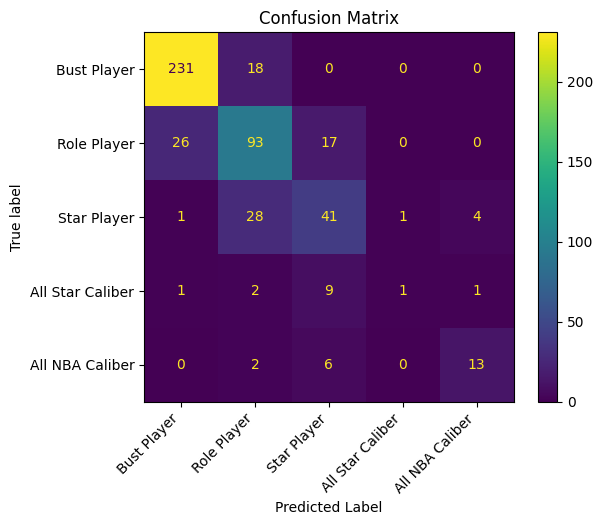

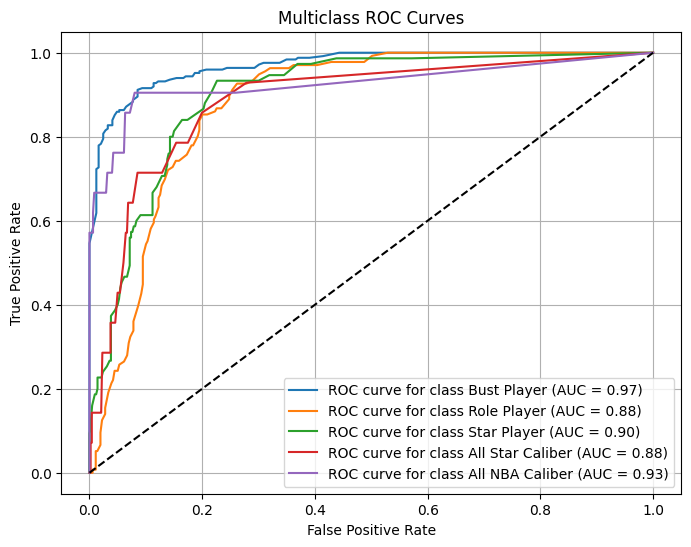

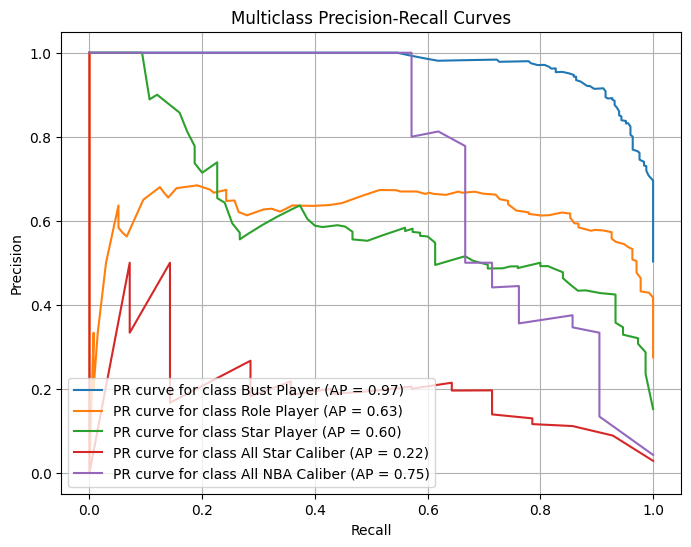



Fold 5 Report
                  precision    recall  f1-score   support

     Bust Player       0.90      0.91      0.90       248
     Role Player       0.70      0.73      0.71       136
     Star Player       0.65      0.70      0.68        76
All Star Caliber       1.00      0.07      0.13        14
 All NBA Caliber       0.63      0.57      0.60        21

        accuracy                           0.79       495
       macro avg       0.78      0.60      0.60       495
    weighted avg       0.80      0.79      0.78       495

Accuracy: 0.7898989898989899
Precision (macro): 0.7759816860879377
Recall (macro): 0.5958914125922016
F1 Score (macro): 0.6049445569658922


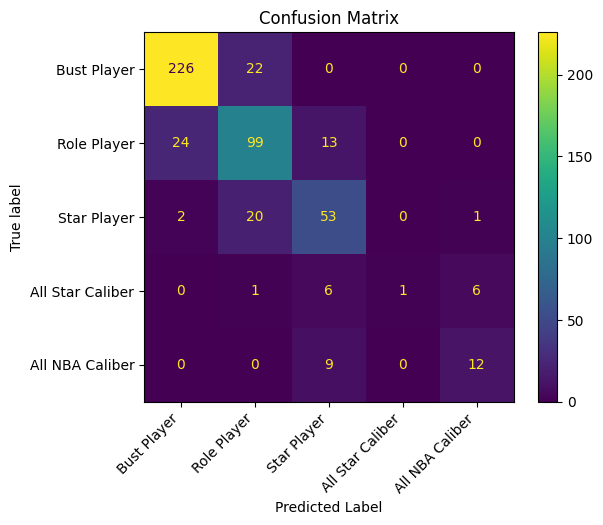

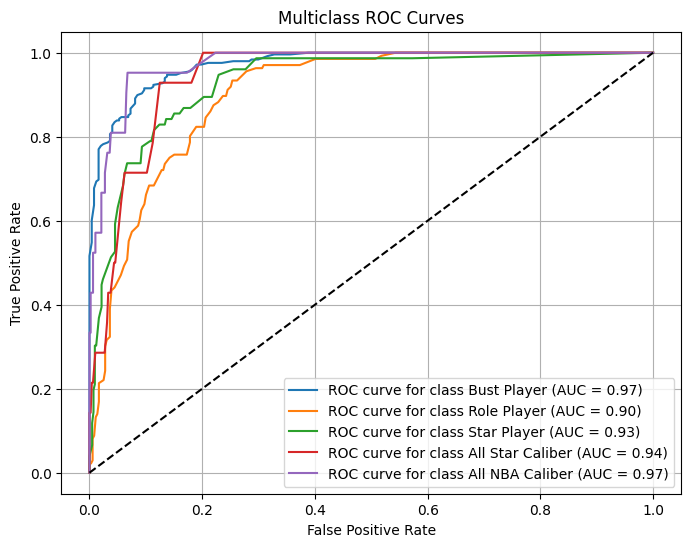

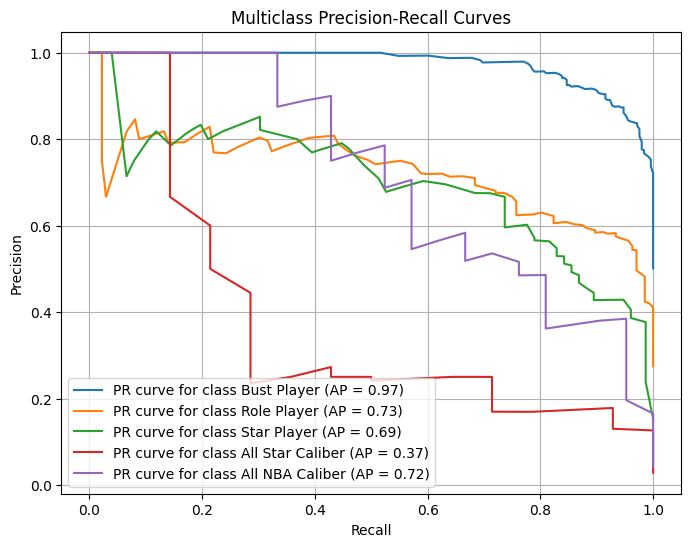

In [63]:
from sklearn.model_selection import StratifiedKFold
import numpy as np

skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

X_np = X.to_pandas()  # Convert Polars DataFrame to pandas for compatibility with preprocessor
for fold, (train_idx, test_idx) in enumerate(skf.split(X_np, y_encoded)):
    X_train, X_test = X_np.iloc[train_idx], X_np.iloc[test_idx]
    y_train, y_test = np.array(y_encoded)[train_idx], np.array(y_encoded)[test_idx]
    
    X_train_processed = preprocessor.fit_transform(X_train)
    X_test_processed = preprocessor.transform(X_test)
    
    model.fit(X_train_processed, y_train)
    preds = model.predict(X_test_processed)
    
    print(f"Fold {fold + 1} Report")
    print_metrics(y_test, preds, target_names)
    print_roc_curve(y_test, model, X_test_processed, target_names)
    print_precision_recall_curve(y_test, model, X_test_processed, target_names)
    print("\n" + "="*50 + "\n")

/Users/rashe/PycharmProjects/PredictingNBACareers/.venv/lib/python3.13/site-packages/sklearn/linear_model/_logistic.py:1272: FutureWarning: 'multi_class' was deprecated in version 1.5 and will be removed in 1.7. From then on, it will always use 'multinomial'. Leave it to its default value to avoid this warning.
  warnings.warn(


                  precision    recall  f1-score   support

     Bust Player       0.91      0.91      0.91       248
     Role Player       0.69      0.75      0.72       136
     Star Player       0.62      0.62      0.62        76
All Star Caliber       0.67      0.14      0.24        14
 All NBA Caliber       0.45      0.48      0.47        21

        accuracy                           0.78       495
       macro avg       0.67      0.58      0.59       495
    weighted avg       0.78      0.78      0.78       495

Accuracy: 0.7797979797979798
Precision (macro): 0.6686913018748706
Recall (macro): 0.5789453472390653
F1 Score (macro): 0.5896144965184809


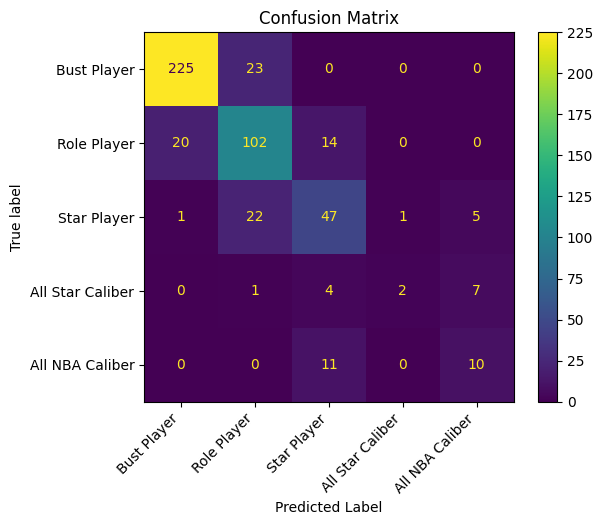

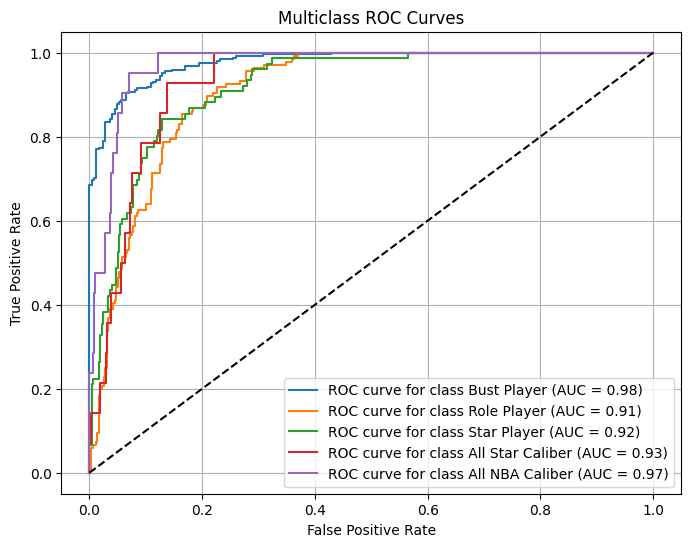

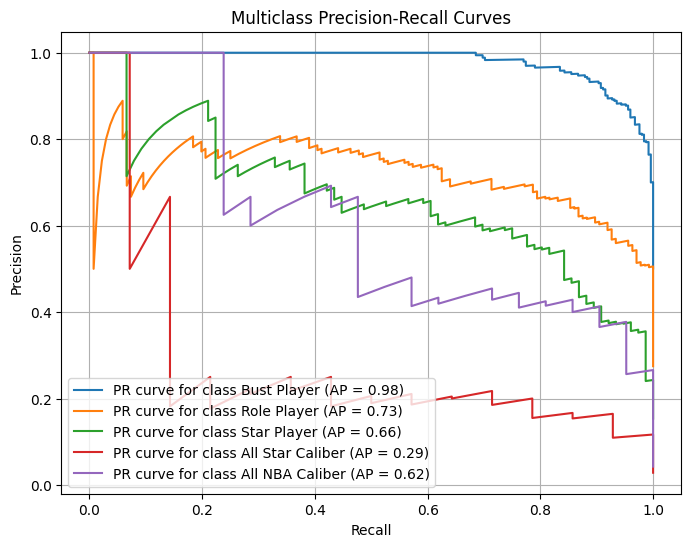

In [64]:
from sklearn.linear_model import LogisticRegression

model = LogisticRegression(
    multi_class='multinomial', 
    max_iter=1000,
    solver='saga',
    random_state=42,
    penalty='l2',
)
model.fit(X_train_processed, y_train)
preds = model.predict(X_test_processed)
print_metrics(y_test, preds, target_names)
print_roc_curve(y_test, model, X_test_processed, target_names)
print_precision_recall_curve(y_test, model, X_test_processed, target_names)

My best model is Random Forest. Now we will use Cross validation and Hyperparameter Tunning to improve performance

In [65]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import cross_val_score

rf = RandomForestClassifier(random_state=42)

scores = cross_val_score(rf, X_train_processed, y_train, cv=5, scoring='accuracy')
print("CV Accuracy scores:", scores)
print("Mean CV Accuracy:", scores.mean())


CV Accuracy scores: [0.79093199 0.78030303 0.77020202 0.75757576 0.74494949]
Mean CV Accuracy: 0.7687924585909472


In [66]:
from sklearn.model_selection import RandomizedSearchCV
from sklearn.ensemble import RandomForestClassifier
from scipy.stats import randint

param_dist = {
    'n_estimators': randint(100, 500),
    'max_depth': [None, 10, 20, 30],
    'min_samples_split': randint(2, 10),
    'min_samples_leaf': randint(1, 10),
    'max_features': ['auto', 'sqrt', 'log2'],
    'bootstrap': [True, False]
}

rf = RandomForestClassifier(random_state=42)
search = RandomizedSearchCV(rf, param_distributions=param_dist, 
                            n_iter=50, cv=5, scoring='accuracy', 
                            random_state=42, n_jobs=-1, verbose=2)

search.fit(X_train_processed, y_train)

print("Best params:", search.best_params_)
print("Best CV score:", search.best_score_)


Fitting 5 folds for each of 50 candidates, totalling 250 fits
[CV] END bootstrap=True, max_depth=30, max_features=auto, min_samples_leaf=8, min_samples_split=6, n_estimators=120; total time=   0.0s
[CV] END bootstrap=True, max_depth=30, max_features=auto, min_samples_leaf=8, min_samples_split=6, n_estimators=120; total time=   0.0s
[CV] END bootstrap=True, max_depth=30, max_features=auto, min_samples_leaf=8, min_samples_split=6, n_estimators=120; total time=   0.0s
[CV] END bootstrap=True, max_depth=30, max_features=auto, min_samples_leaf=8, min_samples_split=6, n_estimators=120; total time=   0.0s
[CV] END bootstrap=True, max_depth=30, max_features=auto, min_samples_leaf=8, min_samples_split=6, n_estimators=120; total time=   0.0s
[CV] END bootstrap=True, max_depth=10, max_features=log2, min_samples_leaf=7, min_samples_split=4, n_estimators=187; total time=   0.5s
[CV] END bootstrap=True, max_depth=10, max_features=log2, min_samples_leaf=7, min_samples_split=4, n_estimators=187; total

/Users/rashe/PycharmProjects/PredictingNBACareers/.venv/lib/python3.13/site-packages/sklearn/model_selection/_validation.py:516: FitFailedWarning: 
100 fits failed out of a total of 250.
The score on these train-test partitions for these parameters will be set to nan.
If these failures are not expected, you can try to debug them by setting error_score='raise'.

Below are more details about the failures:
--------------------------------------------------------------------------------
69 fits failed with the following error:
Traceback (most recent call last):
  File "/Users/rashe/PycharmProjects/PredictingNBACareers/.venv/lib/python3.13/site-packages/sklearn/model_selection/_validation.py", line 859, in _fit_and_score
    estimator.fit(X_train, y_train, **fit_params)
    ~~~~~~~~~~~~~^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "/Users/rashe/PycharmProjects/PredictingNBACareers/.venv/lib/python3.13/site-packages/sklearn/base.py", line 1358, in wrapper
    estimator._validate_params()
    ~~~~

Best params: {'bootstrap': True, 'max_depth': 20, 'max_features': 'sqrt', 'min_samples_leaf': 3, 'min_samples_split': 8, 'n_estimators': 451}
Best CV score: 0.7753479378164517


In [67]:
from sklearn.model_selection import GridSearchCV

param_grid = {
    'n_estimators': [200, 300, 400],
    'max_depth': [10, 20, None],
    'max_features': ['sqrt', 'log2'],
    'min_samples_split': [2, 5],
    'min_samples_leaf': [1, 3]
}

rf = RandomForestClassifier(random_state=42)
grid = GridSearchCV(rf, param_grid=param_grid, 
                    cv=5, scoring='accuracy', n_jobs=-1, verbose=2)

grid.fit(X_train_processed, y_train)
print("Best params:", grid.best_params_)


Fitting 5 folds for each of 72 candidates, totalling 360 fits
[CV] END max_depth=10, max_features=sqrt, min_samples_leaf=1, min_samples_split=2, n_estimators=200; total time=   0.6s
[CV] END max_depth=10, max_features=sqrt, min_samples_leaf=1, min_samples_split=2, n_estimators=200; total time=   0.6s
[CV] END max_depth=10, max_features=sqrt, min_samples_leaf=1, min_samples_split=2, n_estimators=200; total time=   0.7s
[CV] END max_depth=10, max_features=sqrt, min_samples_leaf=1, min_samples_split=2, n_estimators=200; total time=   0.7s
[CV] END max_depth=10, max_features=sqrt, min_samples_leaf=1, min_samples_split=2, n_estimators=200; total time=   0.7s
[CV] END max_depth=10, max_features=sqrt, min_samples_leaf=1, min_samples_split=2, n_estimators=300; total time=   0.9s
[CV] END max_depth=10, max_features=sqrt, min_samples_leaf=1, min_samples_split=2, n_estimators=300; total time=   1.0s
[CV] END max_depth=10, max_features=sqrt, min_samples_leaf=1, min_samples_split=2, n_estimators=30

                  precision    recall  f1-score   support

     Bust Player       0.90      0.91      0.90       248
     Role Player       0.70      0.74      0.72       136
     Star Player       0.66      0.71      0.68        76
All Star Caliber       1.00      0.07      0.13        14
 All NBA Caliber       0.61      0.52      0.56        21

        accuracy                           0.79       495
       macro avg       0.77      0.59      0.60       495
    weighted avg       0.80      0.79      0.78       495

Accuracy: 0.7919191919191919
Precision (macro): 0.7742073170731707
Recall (macro): 0.5911339068734456
F1 Score (macro): 0.6012046460986525


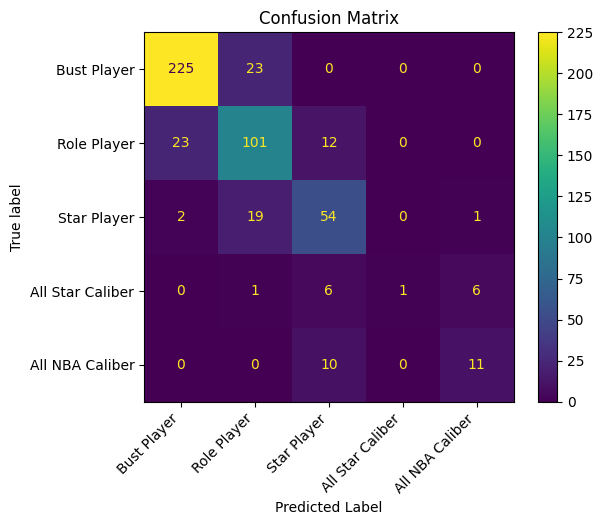

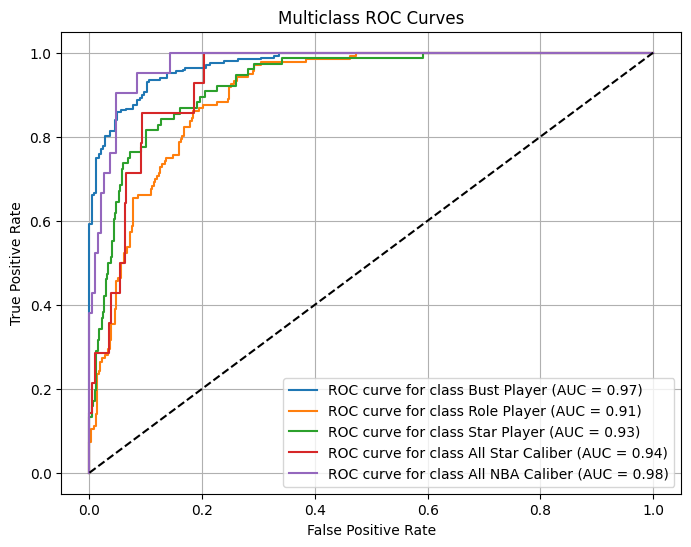

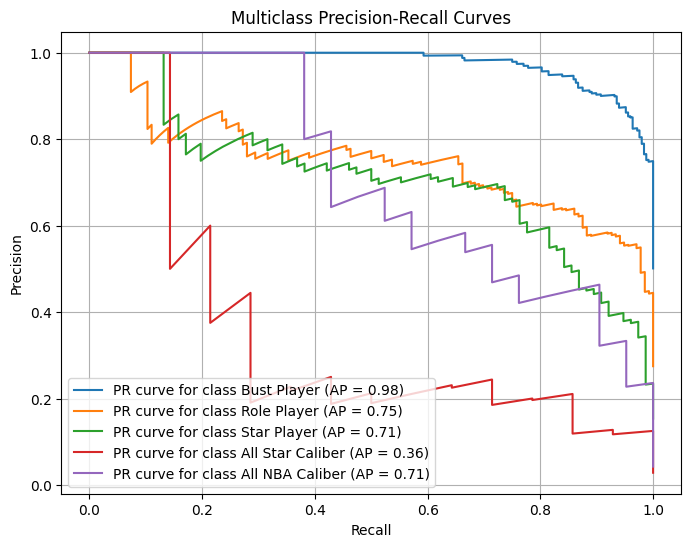

In [68]:
from sklearn.metrics import classification_report

best_model = search.best_estimator_  # or grid.best_estimator_

y_pred = best_model.predict(X_test_processed)
print_metrics(y_test, y_pred, target_names)
print_roc_curve(y_test, best_model, X_test_processed, target_names)
print_precision_recall_curve(y_test, best_model, X_test_processed, target_names)

                  precision    recall  f1-score   support

     Bust Player       0.89      0.91      0.90       248
     Role Player       0.68      0.71      0.70       136
     Star Player       0.65      0.67      0.66        76
All Star Caliber       1.00      0.07      0.13        14
 All NBA Caliber       0.63      0.57      0.60        21

        accuracy                           0.78       495
       macro avg       0.77      0.59      0.60       495
    weighted avg       0.79      0.78      0.77       495

Accuracy: 0.7818181818181819
Precision (macro): 0.7697501756708662
Recall (macro): 0.5876870782268766
F1 Score (macro): 0.5977867920073832


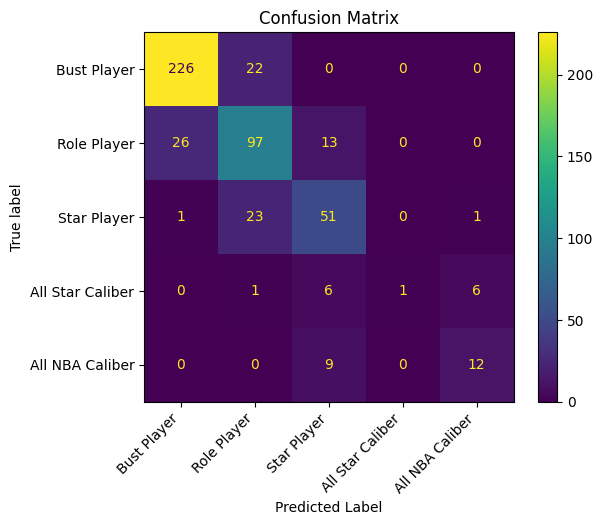

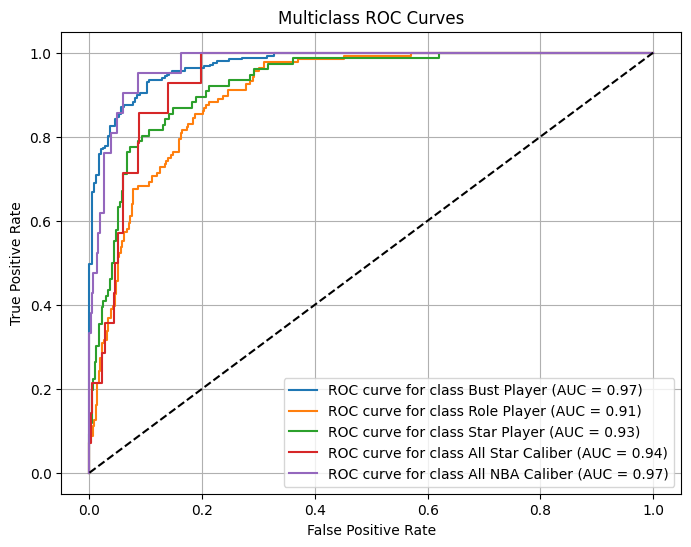

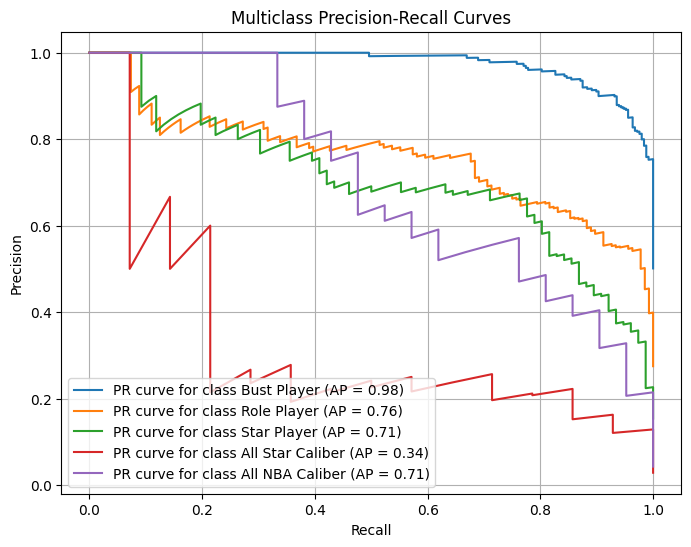

In [69]:

best_model = grid.best_estimator_  # or grid.best_estimator_

y_pred = best_model.predict(X_test_processed)
print_metrics(y_test, y_pred, target_names)
print_roc_curve(y_test, best_model, X_test_processed, target_names)
print_precision_recall_curve(y_test, best_model, X_test_processed, target_names)